# Bike Sharing Case Study – Complete Solution

**Problem:** Investigate bike-sharing demand, perform data quality checks, create useful features, test a hypothesis, build a demand-prediction model, estimate demand capacity, and create a simple natural-language prototype for an operations manager.

## Before running
1. Keep this notebook and the supplied ZIP file in the same folder.
2. If needed, change `ZIP_PATH` in Cell 2 to match your ZIP filename.
3. Run the notebook from top to bottom.
4. The code calculates results from the supplied dataset; numerical results can vary slightly with library versions.

**Important assumption:** `cnt` is hourly rentals, not the number of physical bikes in the fleet. The percentile analysis is therefore an hourly demand-planning benchmark, not an exact physical fleet-size calculation.

## 1. Import libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import re
from pathlib import Path
from scipy import stats

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Extract the supplied dataset

In [5]:
# Keep the ZIP file in the same folder as this notebook.
ZIP_PATH = "bike+sharing+dataset (1) (1).zip"
EXTRACT_FOLDER = Path("bike_data")

if not EXTRACT_FOLDER.exists():
    EXTRACT_FOLDER.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_FOLDER)

print("Dataset extracted successfully.")
print("Files:", [p.name for p in EXTRACT_FOLDER.iterdir()])

Dataset extracted successfully.
Files: ['day.csv', 'hour.csv', 'Readme.txt']


## 3. Load both datasets

In [6]:
hour = pd.read_csv(EXTRACT_FOLDER / "hour.csv")
day = pd.read_csv(EXTRACT_FOLDER / "day.csv")

print("Hourly dataset shape:", hour.shape)
print("Daily dataset shape:", day.shape)

display(hour.head())

Hourly dataset shape: (17379, 17)
Daily dataset shape: (731, 16)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


## 4. Understand the data

In [7]:
print("Hourly dataset information:")
hour.info()

print("\nStatistical summary:")
display(hour.describe())

print("\nColumn names:")
print(hour.columns.tolist())

Hourly dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.4 MB

Statistical summary:


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000



Column names:
['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']


### Important columns
- `dteday`: date
- `season`: season category
- `hr`: hour of the day
- `workingday`: whether it is a working day
- `weathersit`: weather category
- `temp`, `atemp`: normalized temperature and feels-like temperature
- `hum`: normalized humidity
- `windspeed`: normalized wind speed
- `casual`, `registered`: rental counts by user type
- `cnt`: total hourly bike rentals (target variable)

## 5. Data quality checks

In [8]:
# Convert dates to datetime
hour["dteday"] = pd.to_datetime(hour["dteday"])
day["dteday"] = pd.to_datetime(day["dteday"])

print("Missing cell values:", hour.isnull().sum().sum())
print("Duplicate rows:", hour.duplicated().sum())

incorrect_counts = (
    hour["casual"] + hour["registered"] != hour["cnt"]
).sum()
print("Rows where casual + registered != cnt:", incorrect_counts)

print("Date range:", hour["dteday"].min(), "to", hour["dteday"].max())
print("Hour range:", hour["hr"].min(), "to", hour["hr"].max())

Missing cell values: 0
Duplicate rows: 0
Rows where casual + registered != cnt: 0
Date range: 2011-01-01 00:00:00 to 2012-12-31 00:00:00
Hour range: 0 to 23


## 6. Check missing hourly timestamps

In [9]:
# A dataset can have no blank cells but still be missing entire hourly records.
hour["timestamp"] = hour["dteday"] + pd.to_timedelta(hour["hr"], unit="h")

expected_hours = pd.date_range(
    start=hour["timestamp"].min().floor("D"),
    end=hour["timestamp"].max().floor("D") + pd.Timedelta(hours=23),
    freq="h"
)

missing_hours = expected_hours.difference(hour["timestamp"])

print("Expected hourly records:", len(expected_hours))
print("Available hourly records:", hour["timestamp"].nunique())
print("Missing hourly timestamps:", len(missing_hours))

Expected hourly records: 17544
Available hourly records: 17379
Missing hourly timestamps: 165


## 7. Clean the data

We remove duplicate rows if present and sort records chronologically. We do **not** fill missing hourly records with zero because a missing record does not mean that zero bikes were rented.

In [10]:
hour = hour.drop_duplicates()
hour = hour.sort_values(["dteday", "hr"]).reset_index(drop=True)

print("Shape after cleaning:", hour.shape)
print("Missing cell values after cleaning:", hour.isnull().sum().sum())

Shape after cleaning: (17379, 18)
Missing cell values after cleaning: 0


## 8. Feature engineering

In [11]:
# Weekend indicator: in this dataset weekday 0 = Sunday and 6 = Saturday
hour["is_weekend"] = hour["weekday"].isin([0, 6]).astype(int)

# Approximate commuting peak periods on working days
hour["is_rush_hour"] = (
    hour["hr"].isin([7, 8, 9, 16, 17, 18, 19]) &
    (hour["workingday"] == 1)
).astype(int)

# Cyclical encoding: makes midnight close to 11 PM in the feature representation
hour["hour_sin"] = np.sin(2 * np.pi * hour["hr"] / 24)
hour["hour_cos"] = np.cos(2 * np.pi * hour["hr"] / 24)

# Cyclical month encoding
hour["month_sin"] = np.sin(2 * np.pi * (hour["mnth"] - 1) / 12)
hour["month_cos"] = np.cos(2 * np.pi * (hour["mnth"] - 1) / 12)

# Convert normalized values into approximate real-world units for interpretation
hour["temp_c"] = hour["temp"] * 41
hour["atemp_c"] = hour["atemp"] * 50
hour["humidity_pct"] = hour["hum"] * 100
hour["wind_kmh"] = hour["windspeed"] * 67

print("Feature engineering completed.")
display(hour.head())

Feature engineering completed.


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,...,is_weekend,is_rush_hour,hour_sin,hour_cos,month_sin,month_cos,temp_c,atemp_c,humidity_pct,wind_kmh
0,1,2011-01-01,1,0,1,0,0,6,0,1,...,1,0,0.000000,1.000000,0.0,1.0,9.84,14.395,81.0,0.0
1,2,2011-01-01,1,0,1,1,0,6,0,1,...,1,0,0.258819,0.965926,0.0,1.0,9.02,13.635,80.0,0.0
2,3,2011-01-01,1,0,1,2,0,6,0,1,...,1,0,0.500000,0.866025,0.0,1.0,9.02,13.635,80.0,0.0
3,4,2011-01-01,1,0,1,3,0,6,0,1,...,1,0,0.707107,0.707107,0.0,1.0,9.84,14.395,75.0,0.0
4,5,2011-01-01,1,0,1,4,0,6,0,1,...,1,0,0.866025,0.500000,0.0,1.0,9.84,14.395,75.0,0.0


## 9. Exploratory Data Analysis (EDA)

### A. Average rentals by hour

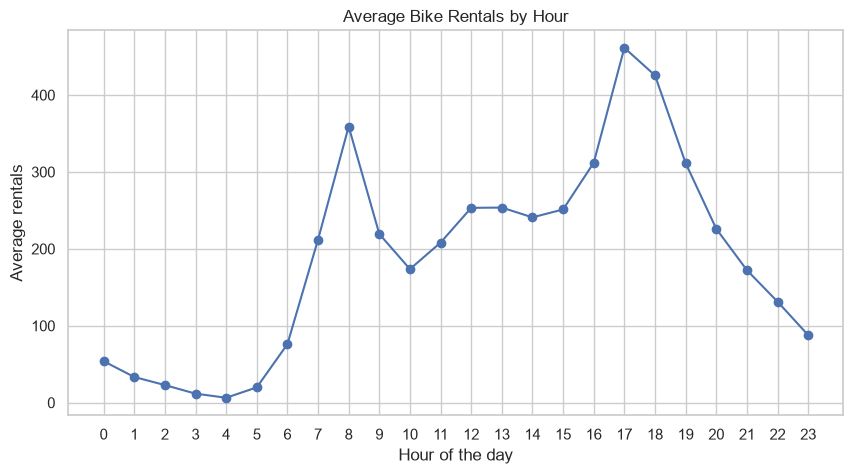

In [12]:
hourly_demand = hour.groupby("hr")["cnt"].mean()

plt.figure(figsize=(10, 5))
plt.plot(hourly_demand.index, hourly_demand.values, marker="o")
plt.title("Average Bike Rentals by Hour")
plt.xlabel("Hour of the day")
plt.ylabel("Average rentals")
plt.xticks(range(24))
plt.grid(True)
plt.show()

### B. Average rentals by month

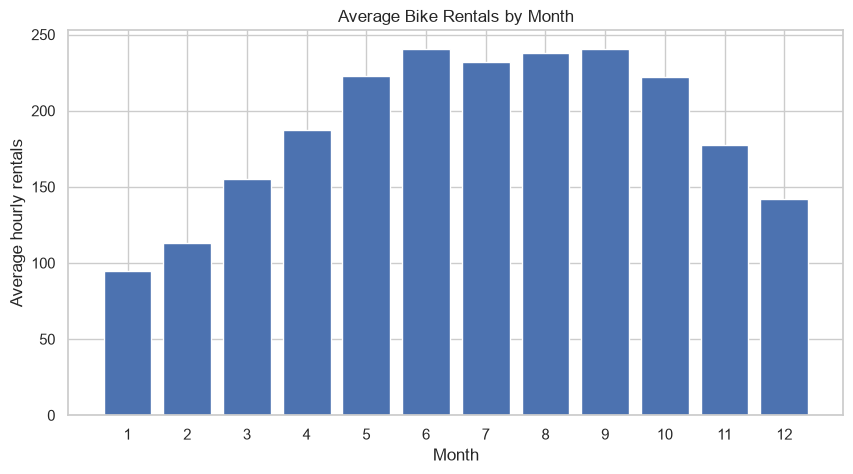

In [13]:
monthly_demand = hour.groupby("mnth")["cnt"].mean()

plt.figure(figsize=(10, 5))
plt.bar(monthly_demand.index, monthly_demand.values)
plt.title("Average Bike Rentals by Month")
plt.xlabel("Month")
plt.ylabel("Average hourly rentals")
plt.xticks(range(1, 13))
plt.show()

### C. Average rentals by season

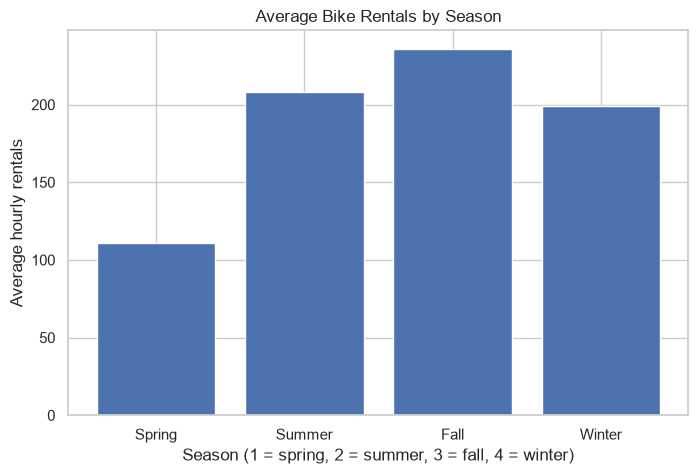

,average_rentals
season,
1,111.114569
2,208.344069
3,236.016237
4,198.868856


In [14]:
season_demand = hour.groupby("season")["cnt"].mean()

plt.figure(figsize=(8, 5))
plt.bar(season_demand.index, season_demand.values)
plt.title("Average Bike Rentals by Season")
plt.xlabel("Season (1 = spring, 2 = summer, 3 = fall, 4 = winter)")
plt.ylabel("Average hourly rentals")
plt.xticks([1, 2, 3, 4], ["Spring", "Summer", "Fall", "Winter"])
plt.show()

display(season_demand.rename("average_rentals").to_frame())

### D. Impact of weather

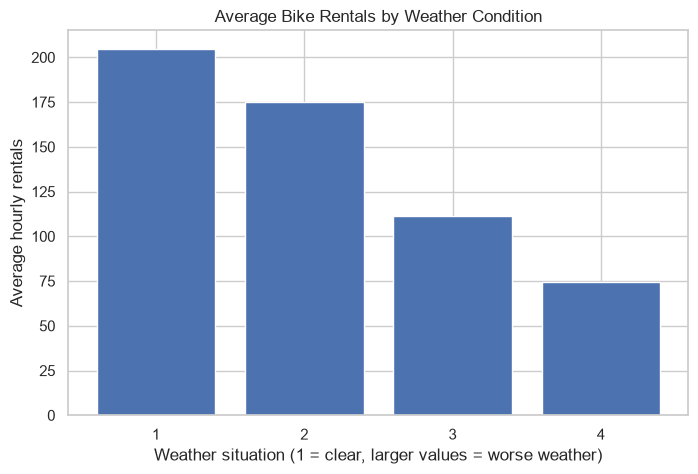

,average_rentals
weathersit,
1,204.869272
2,175.165493
3,111.579281
4,74.333333


In [15]:
weather_demand = hour.groupby("weathersit")["cnt"].mean()

plt.figure(figsize=(8, 5))
plt.bar(weather_demand.index, weather_demand.values)
plt.title("Average Bike Rentals by Weather Condition")
plt.xlabel("Weather situation (1 = clear, larger values = worse weather)")
plt.ylabel("Average hourly rentals")
plt.xticks(weather_demand.index)
plt.show()

display(weather_demand.rename("average_rentals").to_frame())

### E. Working day versus non-working day

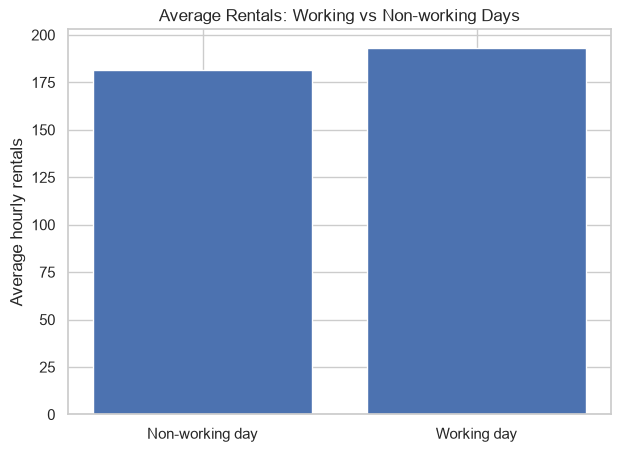

,average_rentals
workingday,
0,181.405332
1,193.207754


In [16]:
working_demand = hour.groupby("workingday")["cnt"].mean()

plt.figure(figsize=(7, 5))
plt.bar(["Non-working day", "Working day"], working_demand.values)
plt.title("Average Rentals: Working vs Non-working Days")
plt.ylabel("Average hourly rentals")
plt.show()

display(working_demand.rename("average_rentals").to_frame())

### F. Correlation heatmap

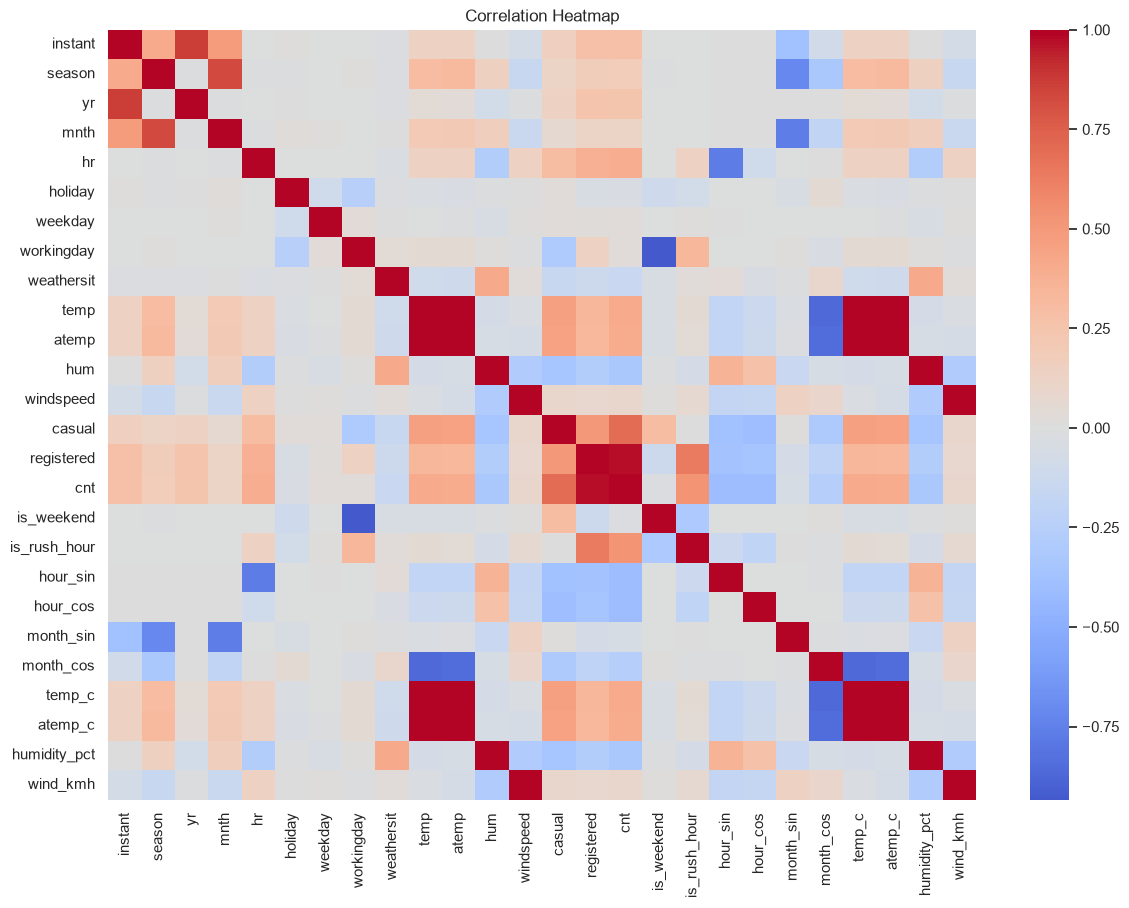

In [17]:
numeric_data = hour.select_dtypes(include=np.number)
correlation = numeric_data.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(correlation, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

## 10. Hypothesis testing

**Question:** Is hourly demand more concentrated into peaks on working days than on non-working days?

- Null hypothesis (H0): Working days do not have a higher peak-to-average demand ratio.
- Alternative hypothesis (H1): Working days have a higher peak-to-average demand ratio.

For each complete day, calculate:

`peak_to_mean = maximum hourly rentals / average hourly rentals`

We use a one-sided Mann–Whitney U test to compare the working-day and non-working-day distributions. This test does not require the two groups to be normally distributed.

In [18]:
daily_groups = hour.groupby("dteday")

daily_data = pd.DataFrame({
    "number_of_hours": daily_groups.size(),
    "peak_to_mean": daily_groups["cnt"].max() / daily_groups["cnt"].mean(),
    "workingday": daily_groups["workingday"].first()
})

# Only use days with all 24 hourly records
daily_data = daily_data[daily_data["number_of_hours"] == 24]

working = daily_data.loc[daily_data["workingday"] == 1, "peak_to_mean"]
non_working = daily_data.loc[daily_data["workingday"] == 0, "peak_to_mean"]

u_stat, p_value = stats.mannwhitneyu(
    working,
    non_working,
    alternative="greater"
)

print("Complete working days:", len(working))
print("Complete non-working days:", len(non_working))
print("Mean peak-to-average ratio (working):", round(working.mean(), 3))
print("Mean peak-to-average ratio (non-working):", round(non_working.mean(), 3))
print("Mann-Whitney U statistic:", u_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("\nDecision: Reject H0.")
    print("There is statistical evidence that working days have more concentrated peak demand.")
else:
    print("\nDecision: Fail to reject H0.")
    print("There is not enough statistical evidence for the alternative hypothesis.")

Complete working days: 443
Complete non-working days: 212
Mean peak-to-average ratio (working): 2.958
Mean peak-to-average ratio (non-working): 2.303
Mann-Whitney U statistic: 89489.0
P-value: 6.616626458067283e-79

Decision: Reject H0.
There is statistical evidence that working days have more concentrated peak demand.


**Interpretation:** If the p-value is below 0.05, the data supports the alternative hypothesis. This identifies a demand pattern; it does not prove that redistribution is better than buying bikes. That requires an operational experiment.

## 11. Build a machine-learning model

We use Random Forest Regression to predict hourly rentals (`cnt`). We exclude `casual` and `registered` because they add up to the target `cnt`, which would leak the answer into the model.

We use a chronological split: older records for training and later records for testing. This is more realistic than randomly splitting time-series data.

In [19]:
features = [
    "season", "yr", "mnth", "hr", "holiday", "weekday",
    "workingday", "weathersit", "temp", "atemp", "hum",
    "windspeed", "hour_sin", "hour_cos", "month_sin",
    "month_cos", "is_weekend", "is_rush_hour"
]

# Train on records before 7 August 2012; test on that date and later
train = hour[hour["dteday"] < "2012-08-07"].copy()
test = hour[hour["dteday"] >= "2012-08-07"].copy()

X_train = train[features]
X_test = test[features]
y_train = train["cnt"]
y_test = test["cnt"]

print("Training records:", len(train))
print("Testing records:", len(test))

Training records: 13891
Testing records: 3488


### Train the Random Forest model

In [20]:
model = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
print("Model trained successfully.")

Model trained successfully.


### Make predictions and evaluate the model

In [21]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model performance")
print("-----------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R-squared:", round(r2, 4))

prediction_results = pd.DataFrame({
    "Actual rentals": y_test.values,
    "Predicted rentals": np.round(y_pred, 1)
})

display(prediction_results.head(10))

Model performance
-----------------
MAE: 45.09
RMSE: 69.57
R-squared: 0.9005


,Actual rentals,Predicted rentals
0,47,46.7
1,18,17.8
2,13,10.1
3,6,5.4
4,9,6.7
5,36,40.4
6,179,159.4
7,502,503.3
8,705,671.1
9,327,336.5


**Metric meaning**
- MAE: average absolute prediction error, in rentals per hour.
- RMSE: prediction error metric that penalises large errors more strongly.
- R-squared: proportion of variation in test demand explained by the model.

Use the values printed by your own notebook as the final results.

### Compare with a simple historical-average baseline

In [22]:
# Baseline: average training demand for the same season, working-day status and hour
baseline_lookup = train.groupby(
    ["season", "workingday", "hr"]
)["cnt"].mean()

test_keys = pd.MultiIndex.from_frame(
    test[["season", "workingday", "hr"]]
)

baseline_pred = baseline_lookup.reindex(test_keys).to_numpy()

# Use the overall training mean if a combination is absent from training data
baseline_pred = np.where(
    np.isnan(baseline_pred),
    y_train.mean(),
    baseline_pred
)

baseline_mae = mean_absolute_error(y_test, baseline_pred)

print("Baseline MAE:", round(baseline_mae, 2))
print("Random Forest MAE:", round(mae, 2))

Baseline MAE: 95.39
Random Forest MAE: 45.09


### Actual versus predicted demand

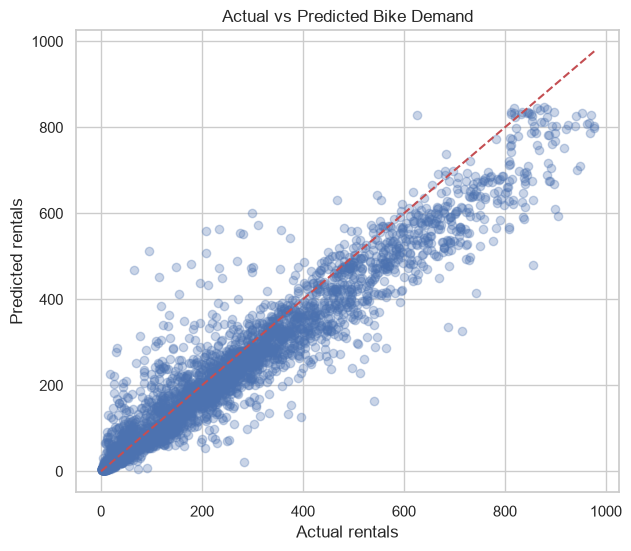

In [23]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.xlabel("Actual rentals")
plt.ylabel("Predicted rentals")
plt.title("Actual vs Predicted Bike Demand")

max_value = max(y_test.max(), np.max(y_pred))
plt.plot([0, max_value], [0, max_value], "r--")
plt.show()

### Feature importance

,Feature,Importance
3,hr,0.371338
17,is_rush_hour,0.134124
9,atemp,0.098854
1,yr,0.076759
8,temp,0.069483
12,hour_sin,0.060070
10,hum,0.042026
13,hour_cos,0.040008
6,workingday,0.034047
7,weathersit,0.015725


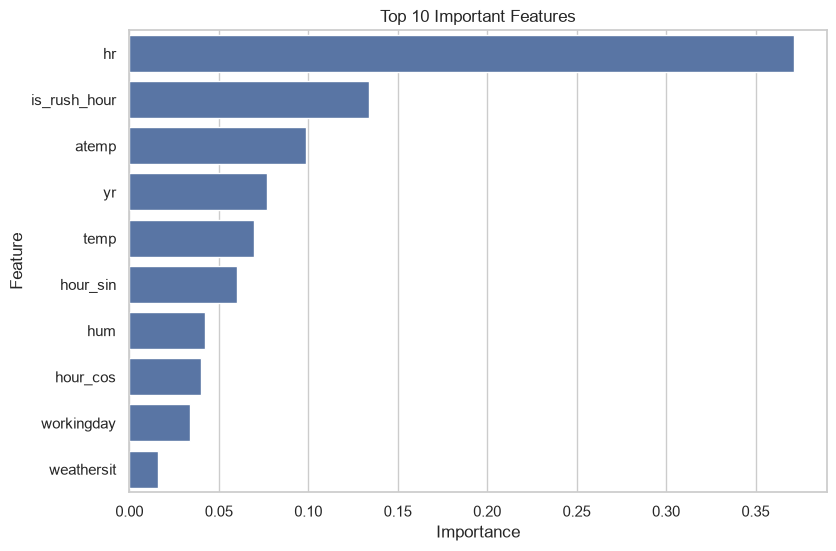

In [24]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance)

plt.figure(figsize=(9, 6))
sns.barplot(data=importance.head(10), x="Importance", y="Feature")
plt.title("Top 10 Important Features")
plt.show()

## 12. Estimate hourly demand capacity

The 2012 hourly rental distribution can provide demand-planning benchmarks. The 95th percentile is the level at or below which 95% of observed hourly demand values fall.

**Important limitation:** This is not the exact number of physical bikes required. The dataset does not provide trip duration, simultaneous bike usage, station inventory, or failed rental requests.

In [25]:
data_2012 = hour[hour["yr"] == 1].copy()

print("2012 hourly demand percentiles")
for percentile in [0.50, 0.90, 0.95, 0.99, 1.00]:
    demand_value = data_2012["cnt"].quantile(percentile)
    print(f"{percentile:.0%}: {np.ceil(demand_value):.0f} rentals per hour")

demand_95 = int(np.ceil(data_2012["cnt"].quantile(0.95)))
demand_max = int(data_2012["cnt"].max())

print("\n95th percentile demand benchmark:", demand_95)
print("Maximum observed hourly rentals:", demand_max)

2012 hourly demand percentiles
50%: 191 rentals per hour
90%: 546 rentals per hour
95%: 663 rentals per hour
99%: 835 rentals per hour
100%: 977 rentals per hour

95th percentile demand benchmark: 663
Maximum observed hourly rentals: 977


### Working-day demand by hour

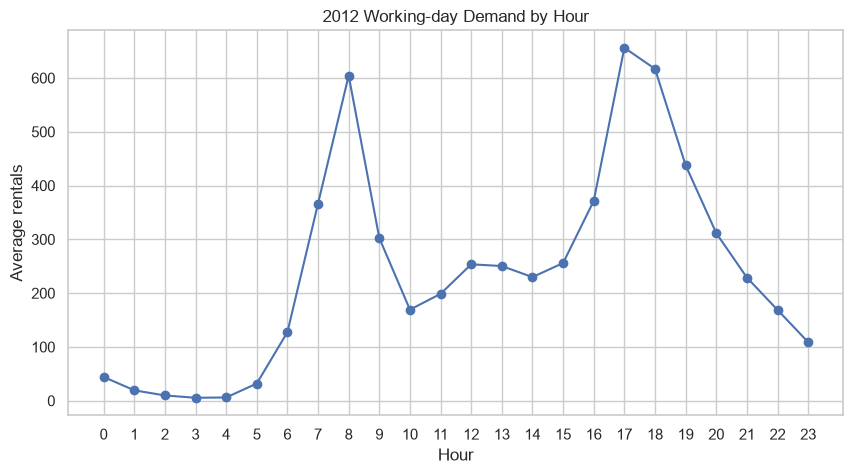

Five busiest average working-day hours:


,average_rentals
hr,
17,656.188755
18,617.000000
8,604.508065
19,437.763052
16,371.542169


In [26]:
working_hour_demand = data_2012[
    data_2012["workingday"] == 1
].groupby("hr")["cnt"].mean()

plt.figure(figsize=(10, 5))
plt.plot(working_hour_demand.index, working_hour_demand.values, marker="o")
plt.title("2012 Working-day Demand by Hour")
plt.xlabel("Hour")
plt.ylabel("Average rentals")
plt.xticks(range(24))
plt.grid(True)
plt.show()

print("Five busiest average working-day hours:")
display(working_hour_demand.sort_values(ascending=False).head(5).to_frame("average_rentals"))

## 13. Natural-language demand prototype

This is a simple rule-based prototype. It recognises a date, a basic weather condition, an optional temperature, a specific hour, or requests for busy/quiet hours. It then uses the trained model to estimate demand for all 24 hours.

The prototype uses typical historical weather for the selected month and hour when weather or temperature is not supplied. It is a demonstration, not a production forecasting service.

In [27]:
# Typical weather values by month and hour, calculated from the historical data
typical_weather = hour.groupby(["mnth", "hr"])[
    ["temp", "atemp", "hum", "windspeed"]
].median()

# Use the most common observed season for each month
season_by_month = hour.groupby("mnth")["season"].agg(
    lambda values: values.mode().iloc[0]
)


def forecast_day(date, weather=1, temp_c=None, holiday=False):
    date = pd.Timestamp(date)
    month = date.month

    # Dataset weekday coding: Sunday=0, Monday=1, ..., Saturday=6
    weekday = (date.dayofweek + 1) % 7
    workingday = int(weekday not in [0, 6] and not holiday)
    season = int(season_by_month.loc[month])

    rows = []

    for h in range(24):
        weather_row = typical_weather.loc[(month, h)]

        temp_value = weather_row["temp"]
        atemp_value = weather_row["atemp"]

        # If the user supplies temperature in Celsius, convert approximately
        # back to the normalized scale used by the original dataset.
        if temp_c is not None:
            temp_value = temp_c / 41
            atemp_value = temp_c / 50

        rows.append({
            "season": season,
            "yr": 1,  # 1 represents 2012 in the original dataset
            "mnth": month,
            "hr": h,
            "holiday": int(holiday),
            "weekday": weekday,
            "workingday": workingday,
            "weathersit": weather,
            "temp": temp_value,
            "atemp": atemp_value,
            "hum": weather_row["hum"],
            "windspeed": weather_row["windspeed"],
            "hour_sin": np.sin(2 * np.pi * h / 24),
            "hour_cos": np.cos(2 * np.pi * h / 24),
            "month_sin": np.sin(2 * np.pi * (month - 1) / 12),
            "month_cos": np.cos(2 * np.pi * (month - 1) / 12),
            "is_weekend": int(weekday in [0, 6]),
            "is_rush_hour": int(
                h in [7, 8, 9, 16, 17, 18, 19] and workingday == 1
            )
        })

    forecast_data = pd.DataFrame(rows)
    forecast_data["predicted_demand"] = model.predict(forecast_data[features])
    return forecast_data

### Ask questions in plain English

In [29]:
def ask_manager(question):
    q = question.lower()

    # Default example date; replace it by writing a date in YYYY-MM-DD format
    date = pd.Timestamp("2012-12-31")

    date_match = re.search(r"\d{4}-\d{2}-\d{2}", q)
    if date_match:
        date = pd.Timestamp(date_match.group())

    if "rain" in q or "snow" in q:
        weather = 3
    elif "cloud" in q or "mist" in q:
        weather = 2
    else:
        weather = 1

    temp_match = re.search(
        r"(\d{1,2})\s*(?:degrees|°c|celsius)\b",
        q
    )
    temperature = float(temp_match.group(1)) if temp_match else None

    holiday = "holiday" in q

    forecast = forecast_day(
        date=date,
        weather=weather,
        temp_c=temperature,
        holiday=holiday
    )

    # Example: "How many rentals at 8am on 2012-07-15?"
    hour_match = re.search(r"\b(\d{1,2})\s*(am|pm)\b", q)
    if hour_match:
        selected_hour = int(hour_match.group(1)) % 12
        if hour_match.group(2) == "pm":
            selected_hour += 12

        demand = forecast.loc[
            forecast["hr"] == selected_hour,
            "predicted_demand"
        ].iloc[0]

        return (
            f"Date: {date.date()}\n"
            f"Hour: {selected_hour}:00\n"
            f"Estimated rentals: {demand:.0f}"
        )

    if "busy" in q or "peak" in q:
        top_hours = forecast.nlargest(3, "predicted_demand")
        return "Busiest hours:\n" + top_hours[
            ["hr", "predicted_demand"]
        ].to_string(index=False)

    if "quiet" in q or "idle" in q:
        quiet_hours = forecast.nsmallest(3, "predicted_demand")
        return "Quietest hours:\n" + quiet_hours[
            ["hr", "predicted_demand"]
        ].to_string(index=False)

    peak = forecast.loc[forecast["predicted_demand"].idxmax()]
    return (
        f"Date: {date.date()}\n"
        f"Busiest hour: {int(peak['hr'])}:00\n"
        f"Estimated rentals: {peak['predicted_demand']:.0f}"
    )

### Test the prototype

In [ ]:
sample_questions = [
    "How many rentals at 8am on 2012-07-15?",
    "How many rentals at 8am on 2012-07-15 if it rains?",
    "Which are the peak hours on 2012-07-15?",
    "Which are the quiet hours on 2012-07-15?",
    "How many bikes are needed on 2012-07-15 at 35 degrees?"
]

for question in sample_questions:
    print("QUESTION:", question)
    print("ANSWER:")
    print(ask_manager(question))
    print("-" * 55)

## 14. Final business recommendation

Based on the analysis:

1. Demand varies significantly by hour, season, and weather.
2. Working-day demand can be more concentrated around peak periods; use the hypothesis-test result printed above.
3. The Random Forest model provides an hourly demand estimate. Report the MAE, RMSE, and R-squared calculated by your notebook.
4. Use the 95th percentile as an hourly demand-planning benchmark, not as an exact fleet count.
5. Do not recommend a large fleet purchase based only on this dataset.

### Recommended operational experiment

- Select comparable station clusters.
- Group A: continue current operations.
- Group B: redistribute bikes before expected peaks.
- Group C: add bikes at selected high-demand locations.
- Run the pilot for at least four weeks.
- Compare failed-rental rate, customer complaints, operating cost, and dock-full events.

If redistribution reduces failed rentals at lower cost, prioritise redistribution. If shortages remain after redistribution, consider targeted purchases.

### Data needed for an exact fleet-size decision

The supplied dataset does not contain station-level inventory, trip duration, bike availability, or failed rental requests. Collect these data before calculating the exact physical fleet requirement.

## 15. Conclusion

This project uses data cleaning, feature engineering, visualisation, statistical hypothesis testing, Random Forest regression, demand percentiles, and a simple natural-language prototype to investigate bike-sharing demand and support an operational decision.